In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import IsolationForest

In [63]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print(train.head())

Train shape: (72161, 12)
Test shape: (48108, 11)
   Id   age  number_dependent_family_members  monthly_income  \
0   1  66.0                              NaN          4000.0   
1   2  61.0                              2.0          4000.0   
2   3  31.0                              2.0          3040.0   
3   4  54.0                              4.0         10218.0   
4   5  29.0                              0.0          4468.0   

   number_of_credit_lines  real_estate_loans  ratio_debt_payment_to_income  \
0                     NaN                1.0                      0.569108   
1                     6.0                1.0                      0.297176   
2                     8.0                0.0                      0.160145   
3                     5.0                0.0                      0.067913   
4                     6.0                0.0                      0.328261   

  credit_line_utilization  number_of_previous_late_payments_up_to_59_days  \
0     0.054887669000

Dataset size consists of training set - 72161 points, test - 48108 points and we have total 11 predictors(features) + 1 target - defaulted on loan.

In [64]:
print("Train overview:")
train.info()
train.describe()
train.columns

Train overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72161 entries, 0 to 72160
Data columns (total 12 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Id                                                72161 non-null  int64  
 1   age                                               65017 non-null  float64
 2   number_dependent_family_members                   67945 non-null  float64
 3   monthly_income                                    66145 non-null  float64
 4   number_of_credit_lines                            66007 non-null  float64
 5   real_estate_loans                                 68355 non-null  float64
 6   ratio_debt_payment_to_income                      66553 non-null  float64
 7   credit_line_utilization                           65815 non-null  object 
 8   number_of_previous_late_payments_up_to_59_days    67966 non-null  float64
 9   n

Index(['Id', 'age', 'number_dependent_family_members', 'monthly_income',
       'number_of_credit_lines', 'real_estate_loans',
       'ratio_debt_payment_to_income', 'credit_line_utilization',
       'number_of_previous_late_payments_up_to_59_days',
       'number_of_previous_late_payments_up_to_89_days',
       'number_of_previous_late_payments_90_days_or_more',
       'defaulted_on_loan'],
      dtype='object')

Missing values:
age                                                 7144
credit_line_utilization                             6346
number_of_credit_lines                              6154
monthly_income                                      6016
number_of_previous_late_payments_up_to_89_days      5845
ratio_debt_payment_to_income                        5608
number_dependent_family_members                     4216
number_of_previous_late_payments_up_to_59_days      4195
real_estate_loans                                   3806
number_of_previous_late_payments_90_days_or_more    3621
dtype: int64


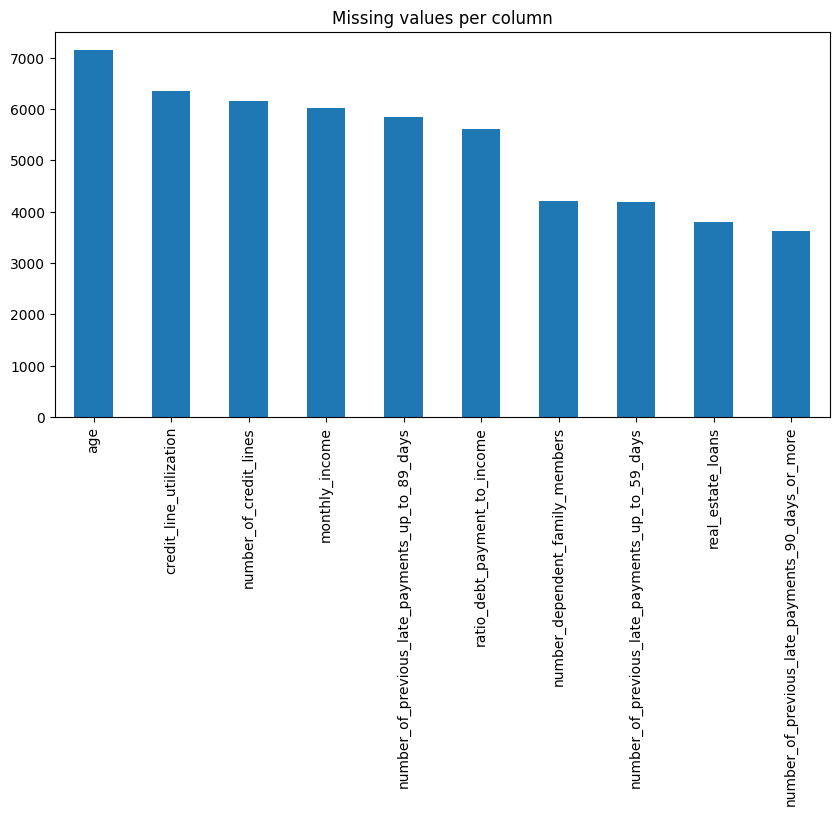

In [65]:
missing = train.isna().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values:")
print(missing)

plt.figure(figsize=(10,5))
missing.plot(kind="bar")
plt.title("Missing values per column")
plt.show()


Missing values are significant in several features (like age, credit line utilization...etc) - based on numbers we have approximately 5-10% of values are missing per feature - it can be due to unavailable records, some customers doesnt have comlete financial history or missing reporting by the bank. At any case this missing valuer should be implicated by out typical strategies (median imptutation).

defaulted_on_loan
0    67148
1     5013
Name: count, dtype: int64


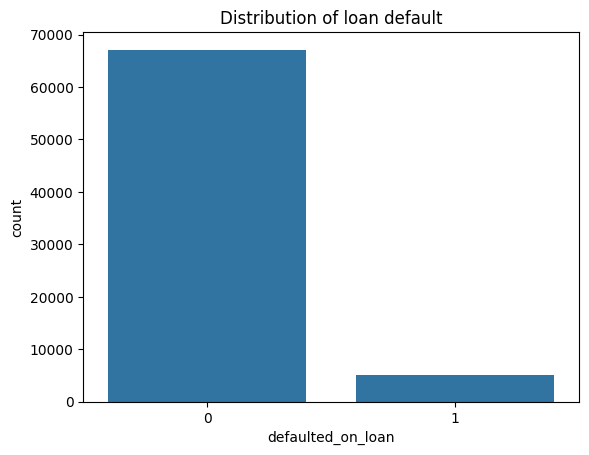

In [66]:
#Target analysis, where target is defaulted_on_loan
#lets check the balance
train["defaulted_on_loan"].value_counts()
train["defaulted_on_loan"].value_counts(normalize=True)
print (train["defaulted_on_loan"].value_counts())
sns.countplot(x="defaulted_on_loan", data=train)

plt.title("Distribution of loan default")
plt.show()


Target has 67k as non-default (meaning 0) and 5k default (1), so ratio is 93%-7% approximately - we have STRONGLY unbalanced dataset, which means that accuracy automatically will be bad metric to look at, and we will be focusing on ROC AUC.

In [67]:
num_cols = train.select_dtypes(include=np.number).columns.tolist()

num_cols.remove("defaulted_on_loan")
num_cols.remove("Id")

num_cols

['age',
 'number_dependent_family_members',
 'monthly_income',
 'number_of_credit_lines',
 'real_estate_loans',
 'ratio_debt_payment_to_income',
 'number_of_previous_late_payments_up_to_59_days',
 'number_of_previous_late_payments_up_to_89_days',
 'number_of_previous_late_payments_90_days_or_more']

In [69]:
for col in train.columns:
    if train[col].dtype == "object":
        train[col] = train[col].str.replace(",", ".", regex=False)
        train[col] = pd.to_numeric(train[col], errors="ignore")

for col in test.columns:
    if test[col].dtype == "object":
        test[col] = test[col].str.replace(",", ".", regex=False)
        test[col] = pd.to_numeric(test[col], errors="ignore")


In [70]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72161 entries, 0 to 72160
Data columns (total 12 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Id                                                72161 non-null  int64  
 1   age                                               65017 non-null  float64
 2   number_dependent_family_members                   67945 non-null  float64
 3   monthly_income                                    66145 non-null  float64
 4   number_of_credit_lines                            66007 non-null  float64
 5   real_estate_loans                                 68355 non-null  float64
 6   ratio_debt_payment_to_income                      66553 non-null  float64
 7   credit_line_utilization                           65815 non-null  float64
 8   number_of_previous_late_payments_up_to_59_days    67966 non-null  float64
 9   number_of_previou

In [71]:
#Unpdate og numerival columns
num_cols = train.select_dtypes(include=np.number).columns.tolist()

num_cols.remove("defaulted_on_loan")
num_cols.remove("Id")

num_cols


['age',
 'number_dependent_family_members',
 'monthly_income',
 'number_of_credit_lines',
 'real_estate_loans',
 'ratio_debt_payment_to_income',
 'credit_line_utilization',
 'number_of_previous_late_payments_up_to_59_days',
 'number_of_previous_late_payments_up_to_89_days',
 'number_of_previous_late_payments_90_days_or_more']

Feature types we had almost all of features to be numerical, but because of , instead of . We had some Dtypes being objects, but in reality they are not, so we can add cycles to replace them and check the dtypes again. As we can see, all predictors are now numerical.

P.S. Can see that now we have one more feature - credit_line_utilization, that was not part of out numerial features before.

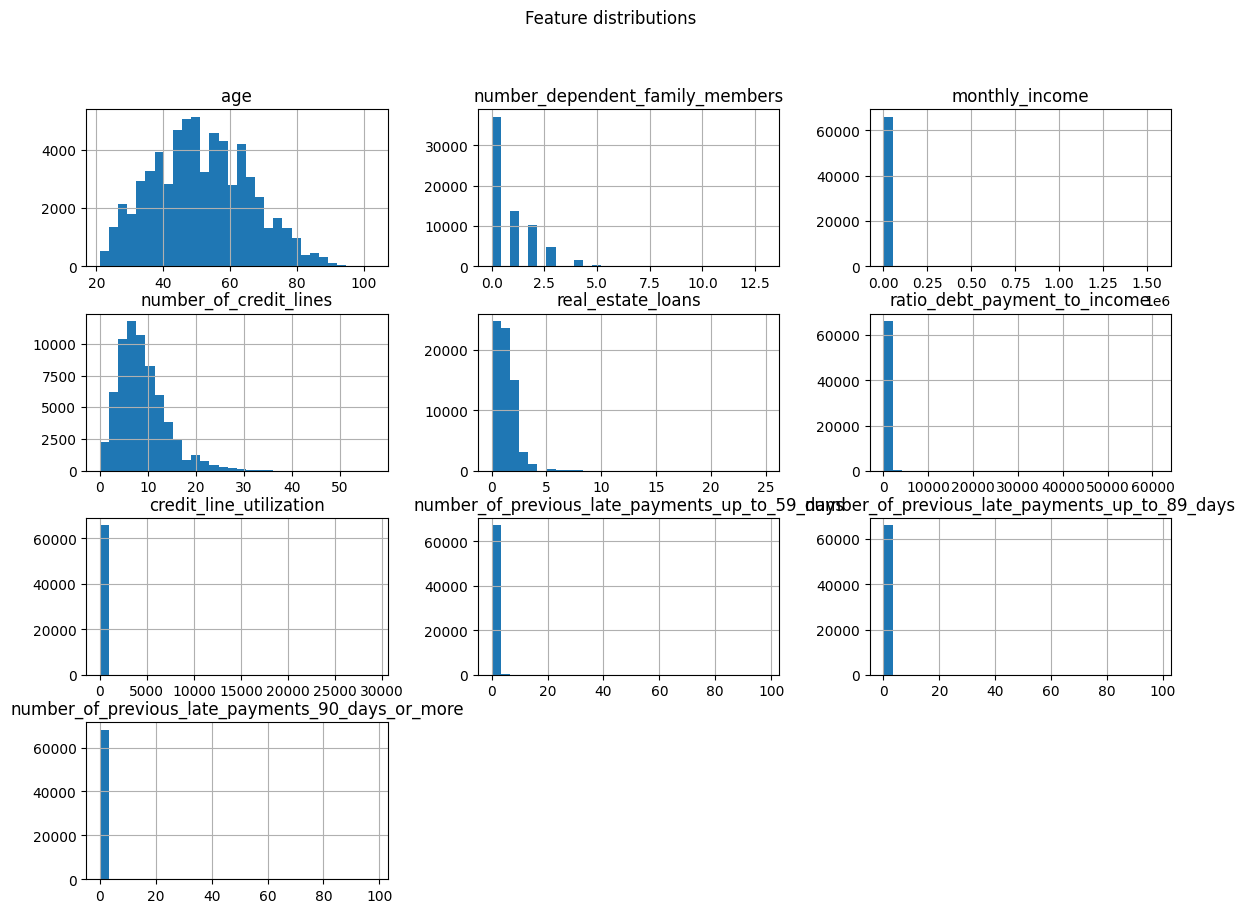

Logaritmic scale for feature Distributions


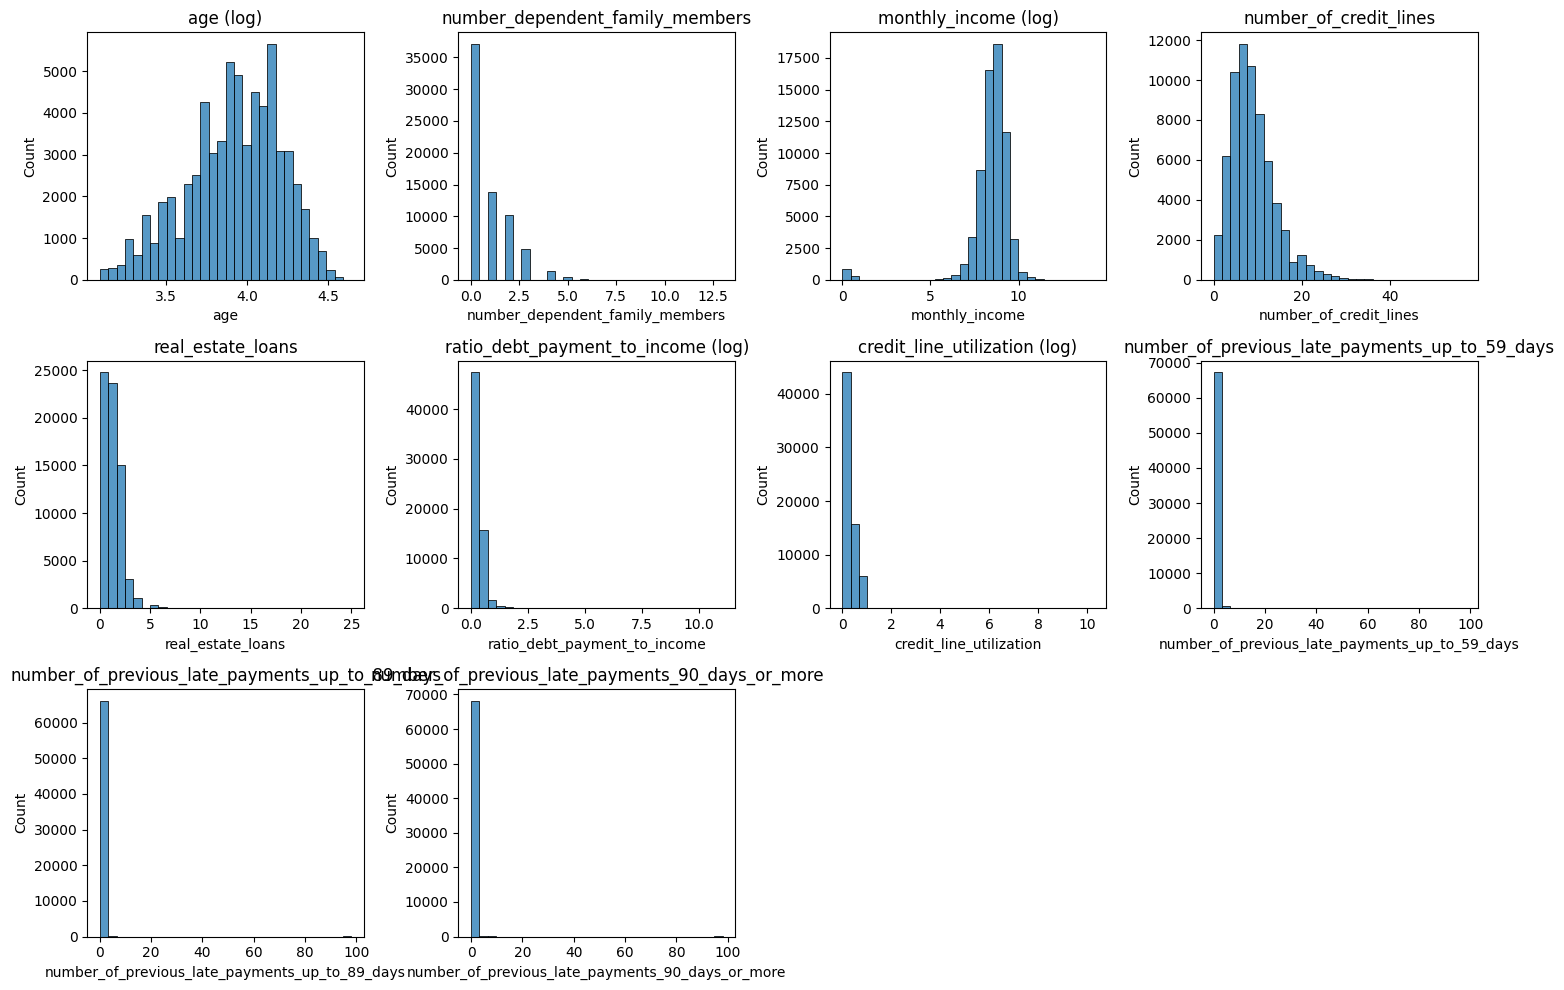

In [72]:
train[num_cols].hist(bins=30, figsize=(14,10))
plt.suptitle("Feature distributions")
plt.show()


"""
Several features represents counts of events, and the peak 0 values is actually very
valuable information (zero-inflated distribution), it is representation of behaviour,
but sometimes if it the most common trend, we dont see small peaks on that scale.

so I add loop through all numerical features, generate one plot per feature 
and if variable has large values in the column or extreme outliers, I plot it with log scale
otherwise the normal plotting.
"""
#I wanted to check some separate values, can be donr with next lines,
#but ideally we just wanna plot all features with zero peaks on log scale and dont touch normal one
#plt.hist(np.log1p(train["monthly_income"]), bins=50)
#plt.title("Log monthly income")
#plt.show()
print (f"Logaritmic scale for feature Distributions")
plt.figure(figsize=(15,10))

for i, col in enumerate(num_cols):

    plt.subplot(3, 4, i+1)
    if train[col].max() > 100:
        sns.histplot(np.log1p(train[col]), bins=30)
        plt.title(f"{col} (log)")
    else:
        sns.histplot(train[col], bins=30)
        plt.title(col)

plt.tight_layout()
plt.show()

Based on the data distributions, we can say the following:
We have different types of features, meaning some are continuous and some are discrete (counts)

Continuous - age, monthly income, ratio_dept_payment_to_income, credit_line_utilization, real_estate_loans
Discrete - that has number in the name (number_dependent_family_members, number_of_credit_lines, number_of_previous_late_payments_up_to_59_days / 89 days /90 and more days)

Identifier ID - not used for modeling and target - defaulted_on_loan is binary.

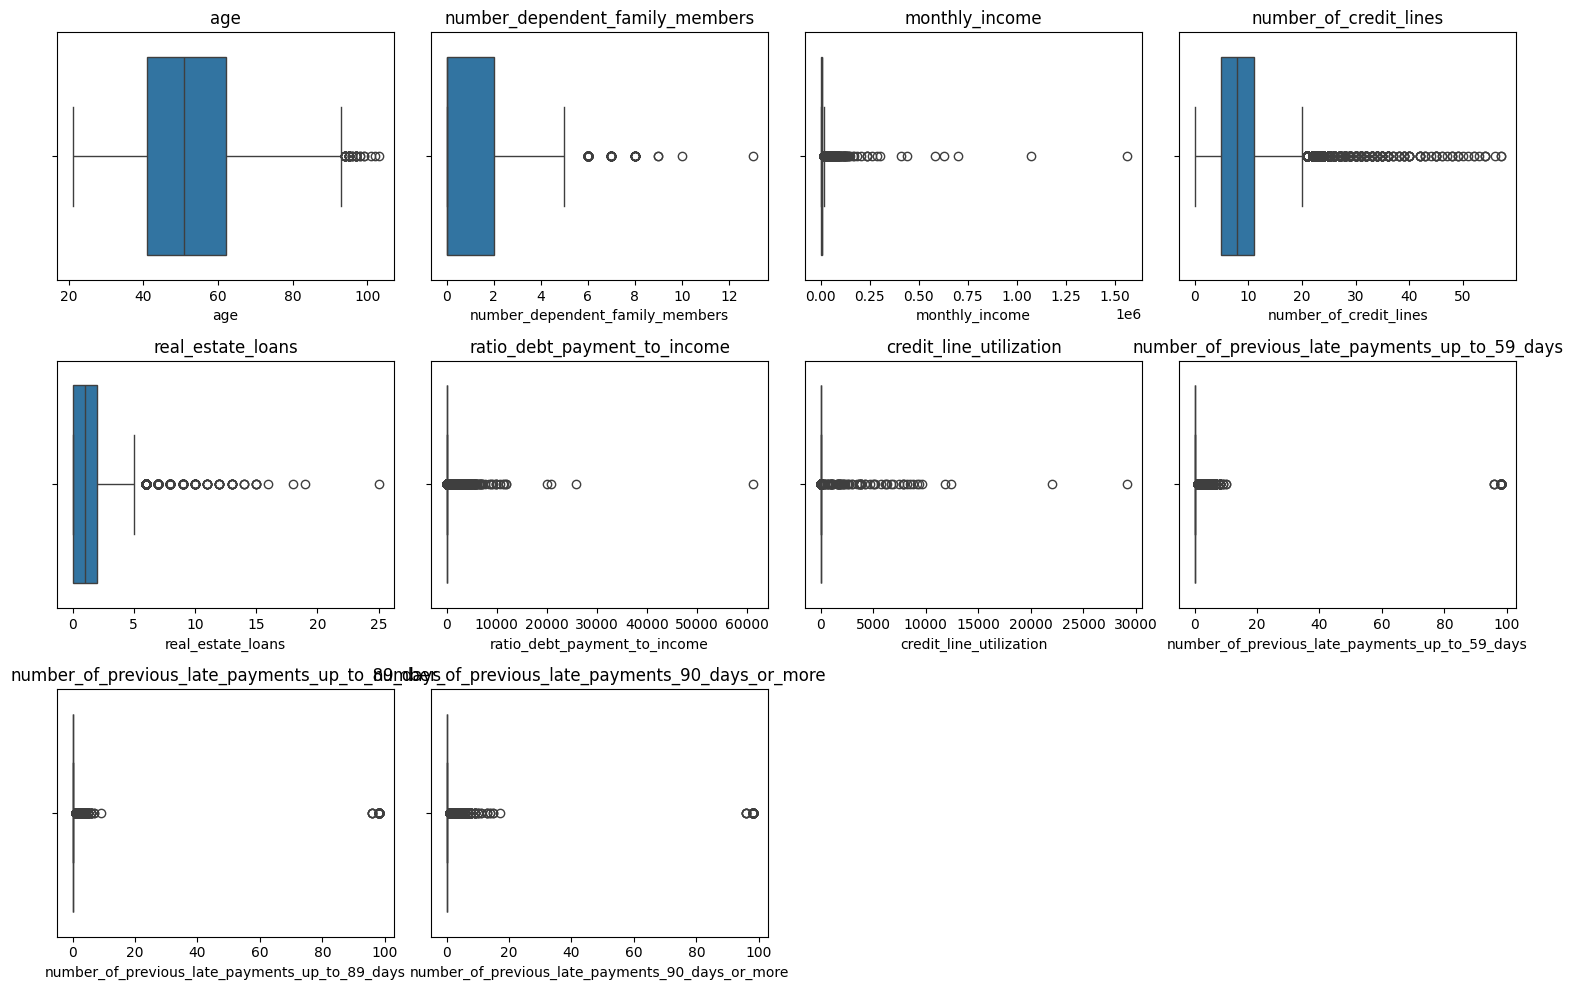

In [75]:
plt.figure(figsize=(15,10))

for i, col in enumerate(num_cols):

    plt.subplot(3,4,i+1)

    sns.boxplot(x=train[col])

    plt.title(col)
    plt.xlabel(col)

plt.tight_layout()
plt.show()

Age is distributed normally, even if there are some outliers (like more than 95 yo) - can be due to data errors or rare elderly clients, but these outliers don't look harmful, especially for tree models

Monthly income - extremely right-skewed - most values 0-20k, but some extreme outliers are more than 1000k - can be high-income customers or possible data noise. 

Credit lines - most customers has 5-12 credit lines, but there are some outliers >40 lines
Real estate loans - most 0-3 real estate loans with some outlier >20 loans

For all late payment feaures we have extreme skewed distributions and most values are 0 and just small fraction is 10+ (later we also will see that these features has correlations between each other)

With box plots we can confirmed that we have a lot of outliers that represents extreme values for clients that we are interested to take into account for our models. But we now that tree models are robust to outliers and also they can possess important information and we dont need?want to remove them and it will also help to compare model performances.

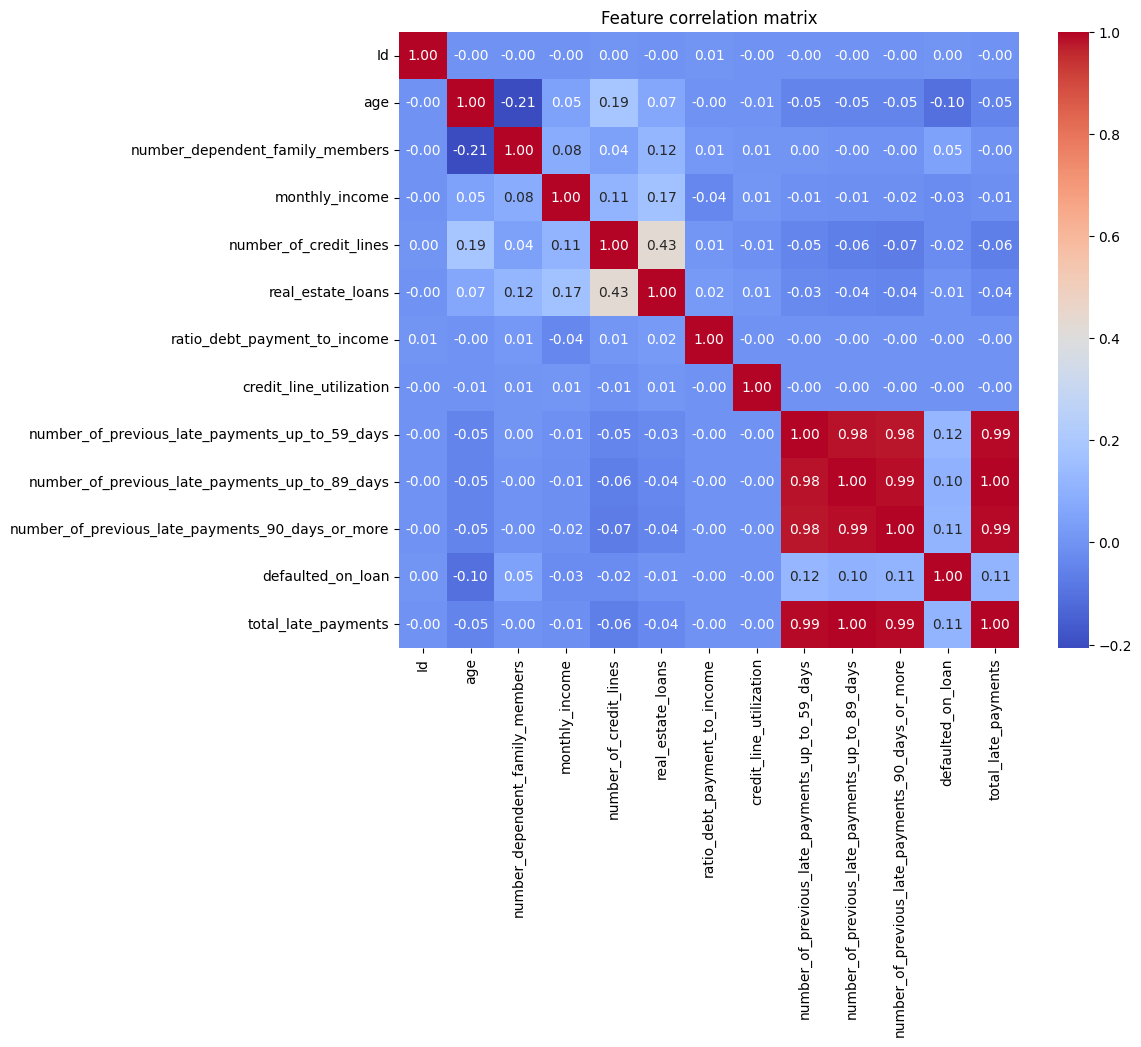

In [79]:
corr = train.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation matrix")
plt.show()


defaulted_on_loan                                   1.000000
number_of_previous_late_payments_up_to_59_days      0.124243
number_of_previous_late_payments_90_days_or_more    0.113465
total_late_payments                                 0.112730
number_of_previous_late_payments_up_to_89_days      0.100133
number_dependent_family_members                     0.047568
Id                                                  0.002038
credit_line_utilization                            -0.002596
ratio_debt_payment_to_income                       -0.004037
real_estate_loans                                  -0.006268
number_of_credit_lines                             -0.024021
monthly_income                                     -0.025232
age                                                -0.104907
Name: defaulted_on_loan, dtype: float64


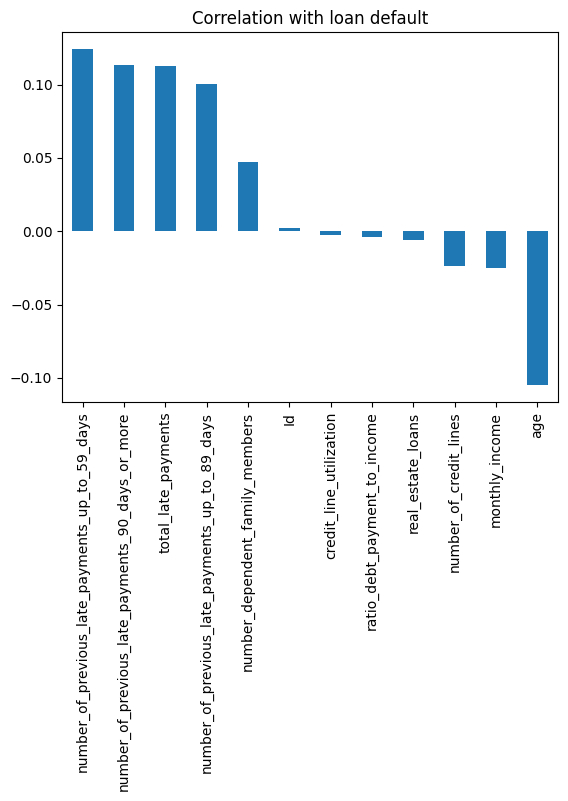

In [80]:
corr_target = corr["defaulted_on_loan"].sort_values(ascending=False)

print(corr_target)

corr_target.drop("defaulted_on_loan").plot(kind="bar")

plt.title("Correlation with loan default")
plt.show()


We can clearly see very high correlations for late payment features (0.98-0.99) - this happens because clients who miss payments do it repeatedly usually and variables contain very similar informations, so I chose to combine them together into total_late_payments feature.
Also these features have quite strong positive correlations with target, which means that past payments have very strong influence and predictors for target.

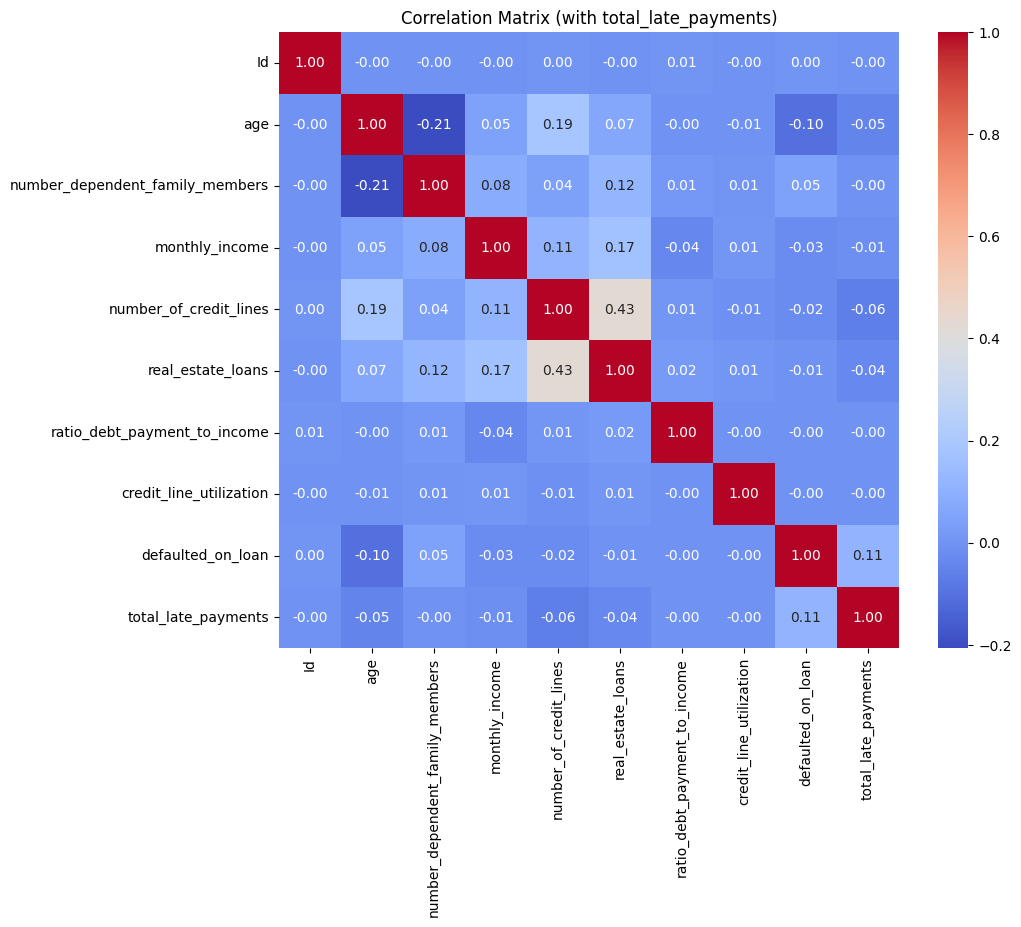

defaulted_on_loan                  1.000000
total_late_payments                0.112730
number_dependent_family_members    0.047568
Id                                 0.002038
credit_line_utilization           -0.002596
ratio_debt_payment_to_income      -0.004037
real_estate_loans                 -0.006268
number_of_credit_lines            -0.024021
monthly_income                    -0.025232
age                               -0.104907
Name: defaulted_on_loan, dtype: float64

In [81]:
# Create a combined feature for late payments

train["total_late_payments"] = (
    train["number_of_previous_late_payments_up_to_59_days"] +
    train["number_of_previous_late_payments_up_to_89_days"] +
    train["number_of_previous_late_payments_90_days_or_more"]
)

corr_df = train.drop(columns=[
    "number_of_previous_late_payments_up_to_59_days",
    "number_of_previous_late_payments_up_to_89_days",
    "number_of_previous_late_payments_90_days_or_more"
])

corr_new = corr_df.corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_new,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix (with total_late_payments)")
plt.show()

corr_new["defaulted_on_loan"].sort_values(ascending=False)

Key insights 
The dataset is highly imbalanced - accuracy isnt good enough metric to use
Strongest predictors of target is late payments
Age has a negative correlation with default - younger customers appear to be riskier
Income and dept ratio show extreme skewness, which seems to benefit from log scaling.

So based on EDA analysis I will look into Logistic Regression, Random forest, Gradient boosting and XGBoost as model to compare in performance.
And as part of feature engineering I will use total_late_payments and log_income and log_dept_ratio. 

/var/folders/65/t81s97s10lddsf8nvt89hrf80000gn/T/ipykernel_42931/2200520722.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_default = train.groupby(age_bins)["defaulted_on_loan"].mean()
/var/folders/65/t81s97s10lddsf8nvt89hrf80000gn/T/ipykernel_42931/2200520722.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_count = train.groupby(age_bins)["defaulted_on_loan"].count()


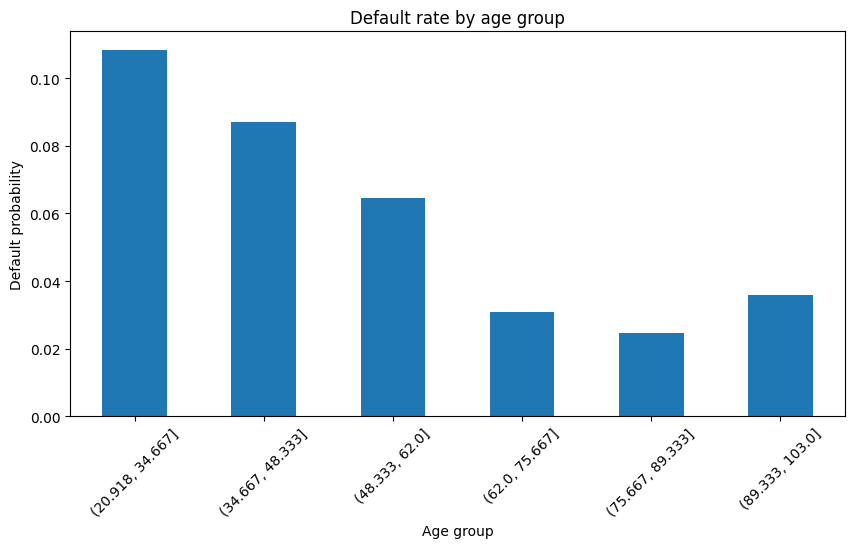

In [92]:
#as additional checking we can see the distribution of loan default probability and how it changes with age
age_bins = pd.cut(train["age"], bins=6)

age_default = train.groupby(age_bins)["defaulted_on_loan"].mean()

age_count = train.groupby(age_bins)["defaulted_on_loan"].count()

plt.figure(figsize=(10,5))

age_default.plot(kind="bar")

plt.title("Default rate by age group")
plt.ylabel("Default probability")
plt.xlabel("Age group")

plt.xticks(rotation=45)

plt.show()

#we can see the default probability decrease with age - 
#older customers tend to have more stable financial behavior. Looks like age is very important predictor